# 07 · Inventory Simulation and Procurement Decisions

The SIMULATED supply side, the reorder policy, and the P0→P4 policy ladder.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


### Everything about supply in this notebook is simulated

Online Retail II is a sales log. Stock, suppliers, lead times, MOQ and costs do not exist in it and are generated by `sim/` from `sim/supply_config.yaml` under a fixed seed.

## The simulated supplier master

In [2]:
sup = pd.read_parquet(resolve(CFG['paths']['simulated']) / 'suppliers.parquet')
print(f'{len(sup):,} rows, {sup["stock_code"].nunique()} SKUs')
display(sup.head(9))
sup[['lead_time_days', 'moq', 'pack_size', 'unit_cost',
     'capacity_units', 'reliability']].describe().round(2)

600 rows, 200 SKUs


,stock_code,supplier_id,lead_time_days,lead_time_cv,moq,pack_size,reliability,median_price,unit_cost,mean_weekly_units,capacity_units,is_simulated,supplier_rank,is_preferred
0,15036,SUP-01,8,0.3390,48,6,0.8193,0.83,0.3817,717.217090,14253,True,1,True
1,15036,SUP-02,2,0.1386,48,12,0.8163,0.83,0.3960,717.217090,4425,True,2,False
2,15036,SUP-03,7,0.1494,24,1,0.8591,0.83,0.4234,717.217090,9891,True,3,False
3,15056BL,SUP-03,6,0.1100,24,24,0.9358,5.95,2.9060,153.683973,2034,True,1,True
4,15056BL,SUP-01,7,0.1942,24,6,0.9832,5.95,3.2981,153.683973,2382,True,2,False
5,15056BL,SUP-02,7,0.2547,12,12,0.8271,5.95,3.5284,153.683973,2529,True,3,False
6,15056N,SUP-01,2,0.1946,24,6,0.8090,5.95,2.9411,166.643299,2218,True,1,True
7,15056N,SUP-03,14,0.1415,12,12,0.8742,5.95,3.0869,166.643299,1494,True,2,False
8,15056N,SUP-02,7,0.1237,24,6,0.8159,5.95,3.6533,166.643299,2288,True,3,False


,lead_time_days,moq,pack_size,unit_cost,capacity_units,reliability
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,6.33,45.76,8.85,2.37,3748.43,0.90
std,3.07,35.24,7.31,2.19,3502.63,0.06
min,2.00,12.00,1.00,0.15,226.00,0.80
25%,4.00,24.00,1.00,1.01,1507.50,0.85
50%,6.00,24.00,6.00,1.75,2718.00,0.90
75%,8.00,72.00,12.00,3.15,4834.00,0.94
max,21.00,144.00,24.00,24.84,22729.00,0.99


## Simulated inventory trajectory for one SKU

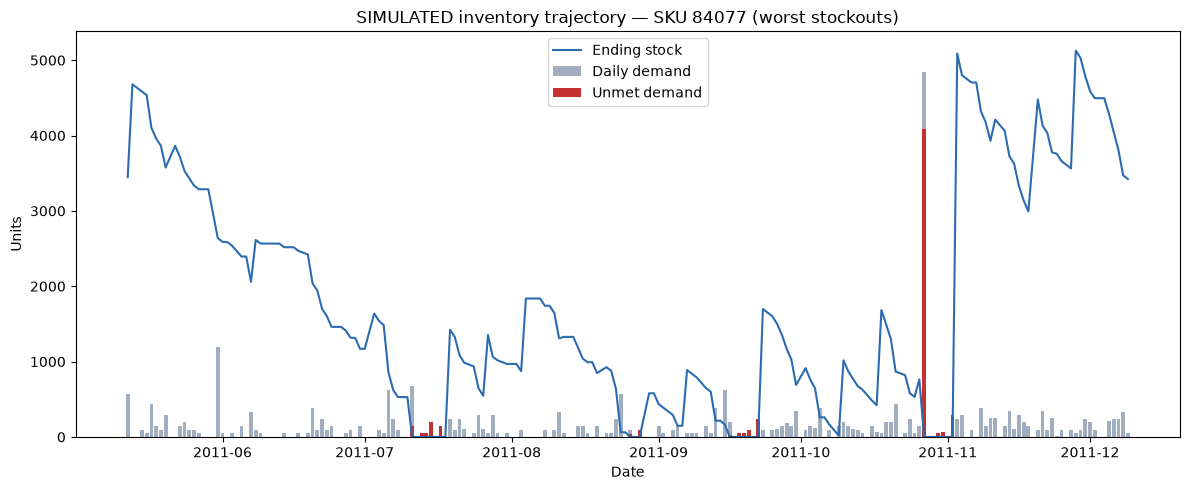

In [3]:
inv = pd.read_parquet(resolve(CFG['paths']['simulated']) / 'inventory_state.parquet')
sku = inv.groupby('stock_code')['unmet_demand'].sum().idxmax()
g = inv[inv['stock_code'] == sku].sort_values('date').tail(180)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(g['date'], g['ending_stock'], label='Ending stock', color='#2b6cb0')
ax.bar(g['date'], g['demand'], color='#a0aec0', label='Daily demand')
ax.bar(g['date'], g['unmet_demand'], color='#c53030', label='Unmet demand')
ax.set_title(f'SIMULATED inventory trajectory — SKU {sku} (worst stockouts)')
ax.set_xlabel('Date'); ax.set_ylabel('Units'); ax.legend()
plt.tight_layout(); plt.show()

## Conservation holds exactly

In [4]:
recon = inv['beginning_stock'] + inv['arrivals'] - inv['consumed']
resid = (recon - inv['ending_stock']).abs()
print(f'max |beginning + arrivals - consumed - ending| = {resid.max():.12f}')
print('negative stock rows:', int((inv['ending_stock'] < -1e-9).sum()))
print(f"baseline fill rate: {1 - inv['unmet_demand'].sum()/inv['demand'].sum():.3%}")

max |beginning + arrivals - consumed - ending| = 0.000000000000
negative stock rows: 0
baseline fill rate: 80.085%


## The reorder calculation, component by component

In [5]:
from xaierp.policy.reorder import decide_reorder
d = decide_reorder(expected_demand_leadtime=420, safety_stock=95,
                   inventory_position=160, lead_time_days=8,
                   moq=48, pack_size=12, supplier_capacity=5000,
                   unit_cost=1.75, mean_daily_demand=30)
for k, v in d.components().items():
    print(f'{v:>+12,.2f}   {k}')
print('-' * 46)
print(f'{d.final_qty:>12,}   FINAL ORDER QUANTITY')
print('\nComponents reconcile:', d.reconciles())

     +420.00   expected demand over lead time
      +95.00   safety stock
     -160.00   less: stock already available / on order
       +0.00   clip at zero (never order negative)
       +0.00   supplier minimum order quantity
       +5.00   pack-size rounding
       +0.00   supplier capacity cap
----------------------------------------------
         360   FINAL ORDER QUANTITY

Components reconcile: True


## The policy ladder

In [6]:
pol = pd.read_csv(REPORTS / 'policy_comparison.csv')
pol[['policy', 'policy_label', 'fill_rate', 'stockout_days', 'n_orders',
     'mean_inventory_units', 'holding_cost', 'shortage_cost',
     'total_cost', 'cost_vs_P0_pct', 'fill_rate_vs_P0_pp']].round(3)

,policy,policy_label,fill_rate,stockout_days,n_orders,mean_inventory_units,holding_cost,shortage_cost,total_cost,cost_vs_P0_pct,fill_rate_vs_P0_pp
0,P0,"P0: Moving average, no safety stock",0.799,2027,1183,473.64,7898.86,386249.50,1086569.55,0.00,0.000
1,P1,P1: Classical reorder point (z*sigma*sqrt(L)),0.887,966,1670,586.28,9504.21,232203.77,1054846.90,-2.92,8.804
2,P2,"P2: ML point forecast, no safety stock",0.792,1570,1788,318.09,5636.97,368160.50,1077804.89,-0.81,-0.711
3,P3,P3: ML forecast + classical safety stock,0.897,767,1678,589.69,9885.89,201177.91,1069475.38,-1.57,9.729
4,P4,P4: ML forecast + quantile safety stock + cons...,0.939,496,1667,792.82,13813.40,125061.54,1136500.29,4.60,13.953


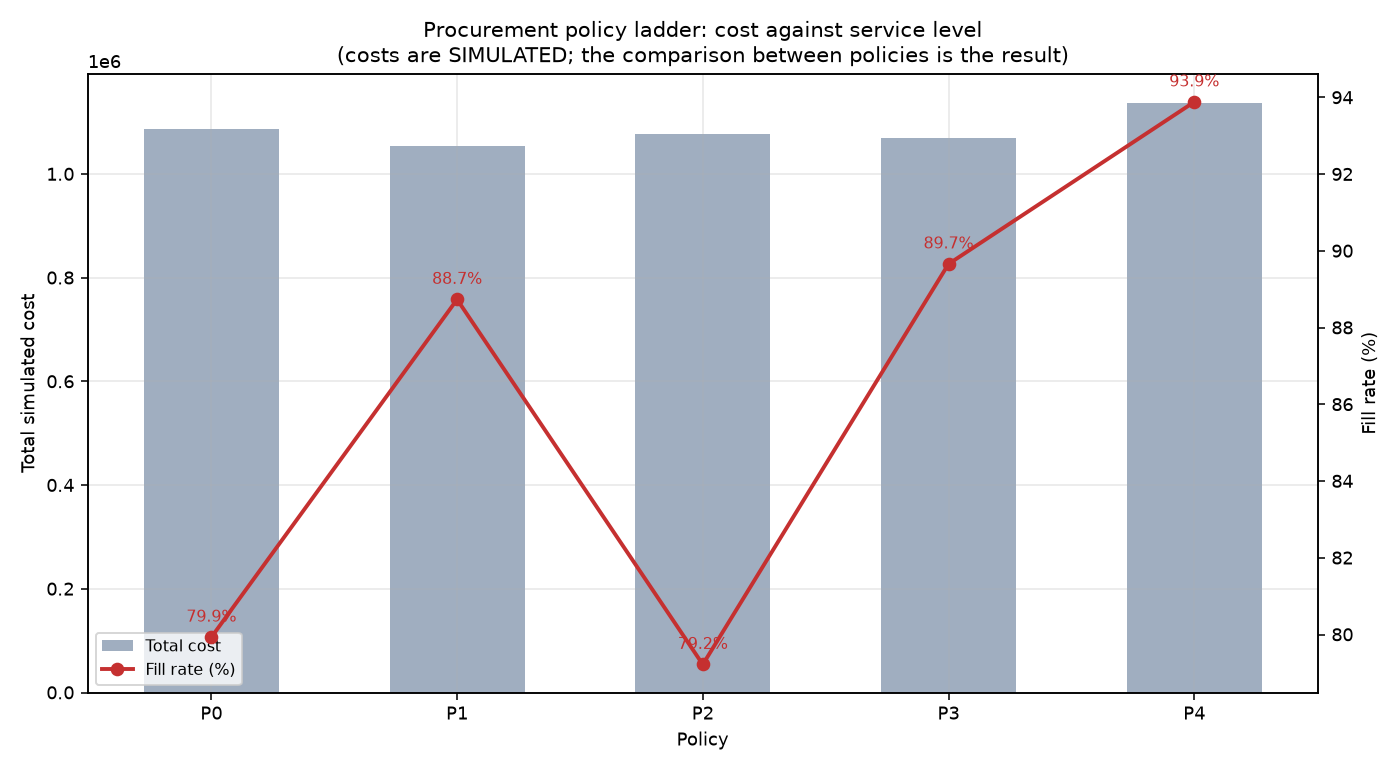

In [7]:
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'policy_cost_vs_fill_rate.png')))

## Ablation — what each capability adds

In [8]:
pd.read_csv(REPORTS / 'ablation_study.csv').round(3)

,stage,policy,fill_rate,stockout_days,mean_inventory_units,total_cost,cost_change_vs_previous_stage,cost_vs_P0_pct
0,A: historical average only,P0,0.799,2027,473.64,1086569.55,NaN,0.00
1,B: + classical safety stock,P1,0.887,966,586.28,1054846.90,-31722.65,-2.92
2,C: ML point forecast,P2,0.792,1570,318.09,1077804.89,22957.99,-0.81
3,D: ML forecast + safety stock,P3,0.897,767,589.69,1069475.38,-8329.51,-1.57
4,E: ML forecast + quantile buffer + supplier co...,P4,0.939,496,792.82,1136500.29,67024.91,4.60


Read this honestly: a better **forecast alone** (P2) does not improve service — it is the explicit treatment of **uncertainty** (a safety buffer, P1/P3/P4) that does. P4 buys the highest fill rate at a higher total cost; whether that trade is worth taking depends on how the business prices a lost sale, which is exactly the judgement a decision support tool should surface rather than make.

## Recommendations produced

In [9]:
rec = pd.read_parquet(resolve(CFG['paths']['results']) / 'procurement_recommendations.parquet')
print(f'{len(rec):,} SKU-day decisions, {rec["rec_reorder"].mean():.1%} recommend a reorder')
comp = ['rec_expected_demand','rec_safety_stock','rec_inventory_offset',
        'rec_clip_adjustment','rec_moq_adjustment','rec_pack_adjustment',
        'rec_capacity_adjustment']
print('max decomposition residual:',
      float((rec[comp].sum(axis=1) - rec['rec_qty']).abs().max()))
rec.loc[rec['rec_reorder'], ['stock_code','date','current_stock',
    'rec_expected_demand','rec_safety_stock','rec_qty','moq','pack_size',
    'rec_order_value']].head(12).round(1)

16,689 SKU-day decisions, 91.5% recommend a reorder
max decomposition residual: 0.0


C:\Users\sandh\AppData\Local\Temp\ipykernel_7276\2049766469.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'rec_order_value']].head(12).round(1)


,stock_code,date,current_stock,rec_expected_demand,rec_safety_stock,rec_qty,moq,pack_size,rec_order_value
5,15036,2011-08-31,2548.4,1052.4,1814.7,324,48,6,123.7
6,15036,2011-09-01,2545.4,847.0,1805.7,108,48,6,41.2
7,15036,2011-09-02,2497.4,723.8,1973.9,204,48,6,77.9
8,15036,2011-09-04,2484.4,722.3,1923.2,162,48,6,61.8
9,15036,2011-09-05,2460.4,781.0,1977.7,300,48,6,114.5
10,15036,2011-09-06,2460.4,768.2,1755.2,66,48,6,25.2
11,15036,2011-09-07,2436.4,613.1,1960.5,138,48,6,52.7
35,15036,2011-10-05,1361.4,601.7,2290.3,1536,48,6,586.3
36,15036,2011-10-06,1349.4,531.8,2182.4,1368,48,6,522.2
37,15036,2011-10-07,1337.4,524.0,2174.7,1362,48,6,519.9
